# Sundarbans channel network — worked example (18 Jan 2016)

One image → water mask → **RivGraph** graph → network parameters.
This is the template we will later loop over 2016–2026 × 3 seasons.

**Input:** `18th Jan 2016.tiff` — Copernicus Browser export of the Sentinel-2 NDWI *visualisation* (8-bit RGB, blue = water, green = land),
georeferenced in UTM 45N (EPSG:32645), ~30 m pixels, 2500 × 1925 px ≈ 75 × 59 km.

We build **two graphs** from the same image, because RivGraph's delta workflow deletes every dead-end channel and the Sundarbans is mostly dead-end tidal creeks:

| Graph | What it is | Used for |
|---|---|---|
| **A. Full tidal network** | every channel RivGraph finds on the land side of the shoreline | loops, dead ends, degree, centrality, connectivity |
| **B. Delta backbone** | RivGraph `prune_network` + `assign_flow_directions`: only channels on an inlet→sea path, directed | Tejedor et al. (2015) metrics via `compute_topologic_metrics` |

Run with the `rivgraph` conda env (kernel *Python (rivgraph)*).

In [1]:
import os, copy, warnings
import numpy as np, pandas as pd, networkx as nx, geopandas as gpd, rasterio
import matplotlib.pyplot as plt
from rasterio import features
from shapely.geometry import Point, shape, box
from shapely.ops import unary_union, linemerge
from skimage import morphology
from rivgraph.classes import delta
from rivgraph import geo_utils as gu, ln_utils as lnu
from rivgraph.deltas import delta_utils as du
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

SRC = '18th Jan 2016.tiff'
OUT = 'example_2016'
os.makedirs(OUT, exist_ok=True)

## 1. Load the image

CRS EPSG:32645, pixel 30.2 x 30.6 m, size 2500 x 1925 px = 75.5 x 58.9 km


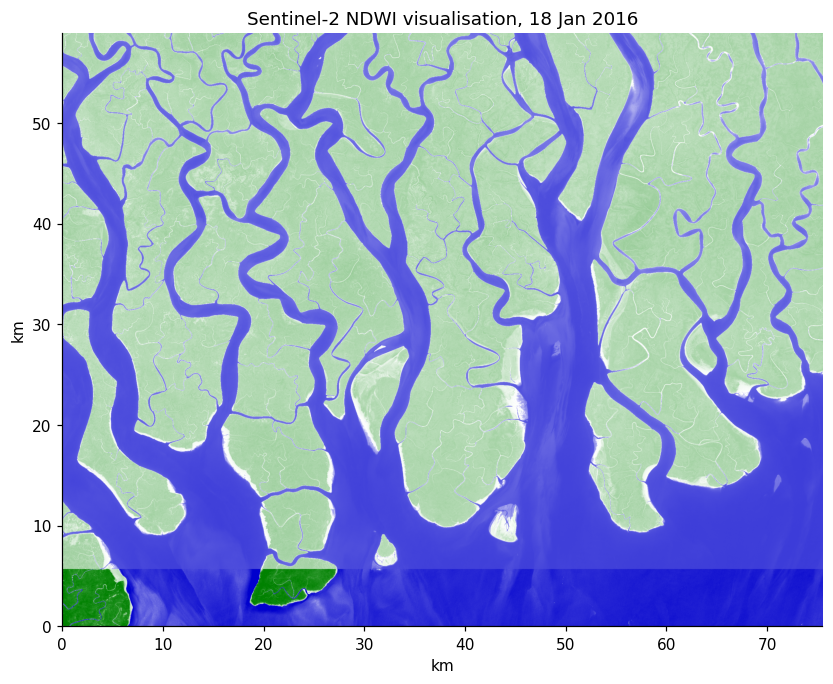

In [2]:
with rasterio.open(SRC) as s:
    rgb = s.read()                      # (3, H, W) uint8
    prof, T, CRS = s.profile, s.transform, s.crs
H, W = rgb.shape[1:]
px_x, px_y = T.a, -T.e
west, south, east, north = rasterio.transform.array_bounds(H, W, T)
EXT_KM = [0, (east - west) / 1e3, 0, (north - south) / 1e3]   # plot extent in km from SW corner
print(f'CRS {CRS}, pixel {px_x:.1f} x {px_y:.1f} m, size {W} x {H} px = {EXT_KM[1]:.1f} x {EXT_KM[3]:.1f} km')

fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(np.moveaxis(rgb, 0, -1), extent=EXT_KM); ax.set_xlabel('km'); ax.set_ylabel('km')
ax.set_title('Sentinel-2 NDWI visualisation, 18 Jan 2016'); plt.show()

## 2. Water mask

In this colour ramp water is blue and land is green, so `blue − green` is strongly bimodal
(land ≈ −40, water > +100). A fixed threshold of 0 is used instead of Otsu so that the
rule is identical for every date. (For the real time series, export the raw 32-bit NDWI and threshold NDWI > 0.)

Note the darker strip at the bottom: a second Sentinel-2 tile with a different stretch. The `B − G` rule handles both.

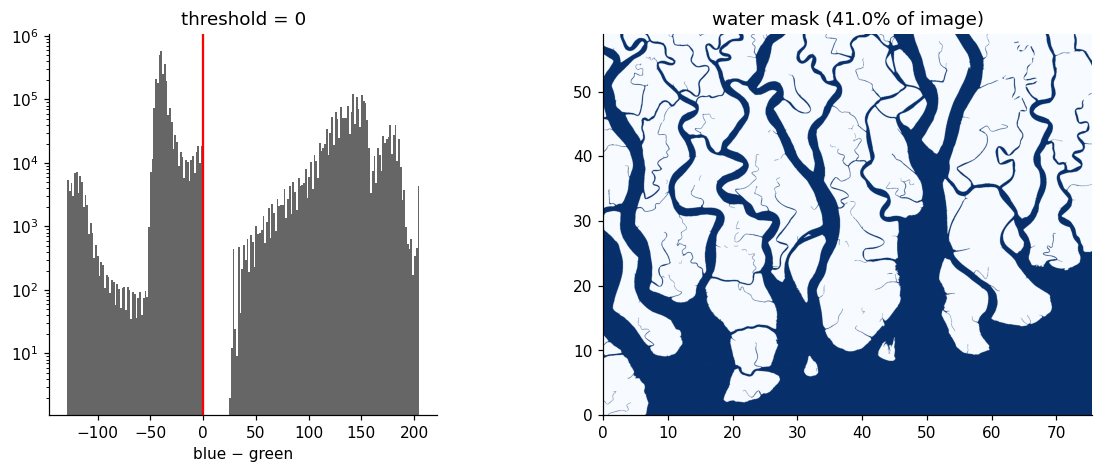

In [3]:
R, G, B = rgb.astype(np.int16)
water = (B - G) > 0
water = morphology.remove_small_objects(water, 30)     # < 30 px (~2.7 ha) specks
water = morphology.remove_small_holes(water, 30)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={'width_ratios': [1, 1.6]})
axs[0].hist((B - G).ravel(), bins=200, color='0.4'); axs[0].axvline(0, color='r')
axs[0].set_xlabel('blue − green'); axs[0].set_title('threshold = 0'); axs[0].set_yscale('log')
axs[1].imshow(water, cmap='Blues', extent=EXT_KM); axs[1].set_title(f'water mask ({water.mean():.1%} of image)')
plt.show()

with rasterio.open(f'{OUT}/mask.tif', 'w', **{**prof, 'count': 1, 'compress': 'lzw'}) as d:
    d.write(water.astype('uint8'), 1)

## 3. Shoreline and inlets (needed by RivGraph's delta workflow)

RivGraph's docs draw these by hand in QGIS. To make the step repeatable over 33 images we generate them automatically:

* **Shoreline:** close the land mask with an 80-px (~2.4 km) disk (done at ¼ resolution for speed). This bridges river mouths up to ~5 km wide, and the boundary of the result is the shoreline line.
  The widest estuary (centre-right) stays open, so the line runs some way up it. Larger disks start cutting arcs into the open sea.
* **Inlets:** channel ends touching the top, left or right edge of the image on the land side. The crop cuts these channels, so water enters the network there.

Warning 1: DeprecationWarning: 'Memory' driver is deprecated since GDAL 3.11. Use 'MEM' onwards. Further messages of this type will be suppressed.


shoreline length 237 km; delta-plain (closed land) area 3423 km²


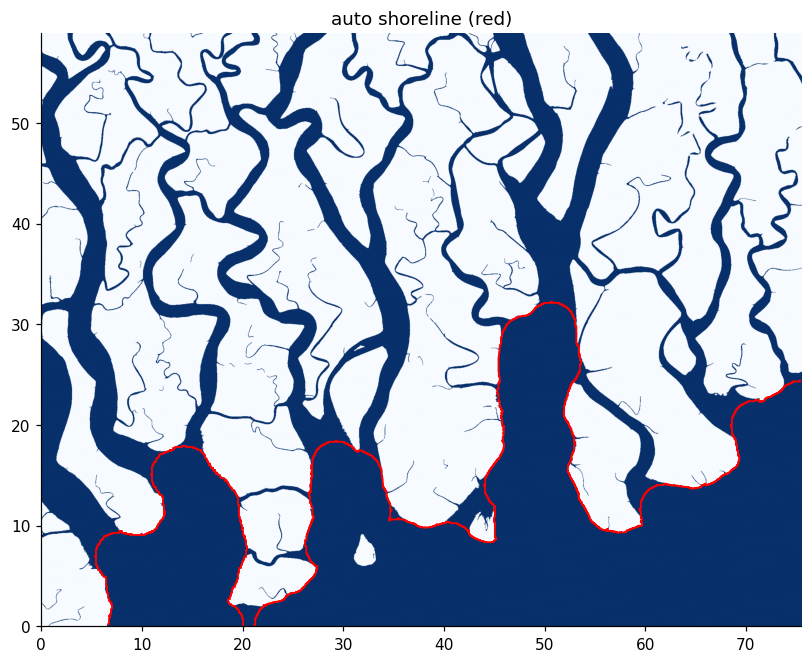

In [4]:
from skimage import transform

def closed_land(water, r=80, f=4):
    small = transform.downscale_local_mean((~water).astype(float), (f, f)) > 0.5
    rs = r // f
    pad = np.pad(small, rs, mode='reflect')                        # reflect so the image edge isn't treated as land or sea
    cl = morphology.binary_closing(pad, morphology.disk(rs))[rs:-rs, rs:-rs]
    cl = morphology.remove_small_holes(cl, 3000)                   # fill inland water bodies only
    cl = (transform.resize(cl.astype(float), water.shape, order=0) > 0.5) | ~water
    return morphology.remove_small_objects(cl, 20000)

land_closed = closed_land(water, r=80)
landpoly = unary_union([shape(g) for g, v in features.shapes(land_closed.astype('uint8'), transform=T) if v == 1])
inner = box(west + 90, south + 90, east - 90, north - 90)          # drop the image frame
shore = landpoly.boundary.intersection(inner)
shore = linemerge(shore) if shore.geom_type == 'MultiLineString' else shore
gpd.GeoDataFrame({'id': [0]}, geometry=[shore], crs=CRS).to_file(f'{OUT}/shoreline.gpkg')   # 'id' column is required by RivGraph's sjoin
print(f'shoreline length {shore.length/1e3:.0f} km; delta-plain (closed land) area {landpoly.area/1e6:.0f} km²')
fig, ax = plt.subplots(figsize=(9, 7))
ax.imshow(water, cmap='Blues', extent=EXT_KM)
gpd.GeoSeries([shore]).translate(-west, -south).scale(1e-3, 1e-3, origin=(0, 0)).plot(ax=ax, color='r', lw=1.2)
ax.set_title('auto shoreline (red)'); plt.show()

## 4. RivGraph: skeleton → links & nodes

In [5]:
rn = delta('sund2016', f'{OUT}/mask.tif', results_folder=f'{OUT}/rivgraph', verbose=False)
rn.skeletonize()
rn.compute_network()
rn.compute_link_width_and_length()
print(f"raw RivGraph network: {len(rn.links['id'])} links, {len(rn.nodes['id'])} nodes")

def node_rc(nodes):
    return np.unravel_index(nodes['idx'], rn.imshape)

def link_keep_land(links, frac=0.5):
    # keep links whose pixels are mostly on the land side (inside the closed-land polygon)
    return [lid for lid, idx in zip(links['id'], links['idx'])
            if land_closed.flat[np.asarray(idx)].mean() > frac]

# inlet points: degree-1 nodes on the top/left/right image edge, on the land side
Gr = nx.MultiGraph(); Gr.add_nodes_from(rn.nodes['id'])
for a, b in rn.links['conn']: Gr.add_edge(a, b)
r, c = node_rc(rn.nodes)
edge = (r <= 2) | (c <= 2) | (c >= W - 3)
inl = [i for i in range(len(r)) if edge[i] and Gr.degree(rn.nodes['id'][i]) == 1 and land_closed[r[i], c[i]]]
xy = gu.idx_to_coords([rn.nodes['idx'][i] for i in inl], rn.imshape, rn.gt)
gpd.GeoDataFrame(geometry=[Point(x, y) for x, y in zip(*xy)], crs=CRS).to_file(f'{OUT}/inlets.gpkg')
print(f'{len(inl)} inlet points on the image edge')

raw_links, raw_nodes = copy.deepcopy(rn.links), copy.deepcopy(rn.nodes)

raw RivGraph network: 927 links, 934 nodes
33 inlet points on the image edge


### 4a. Graph A — full tidal network

All links on the land side of the shoreline. Counts, lengths and loops use every component. Path-based measures (betweenness, efficiency, λ₂, Kirchhoff, diameter) use the largest connected component.
Separate components are other estuary systems that only meet in the sea, plus small creeks that break up at 30 m.
Built as a `networkx.MultiGraph` so that **parallel channels around a small island are kept as two edges** (a plain `nx.Graph`, as in the earlier notebook, merges them and loses the loop).

In [6]:
def to_multigraph(links, nodes, keep=None):
    keep = set(links['id']) if keep is None else set(keep)
    r, c = node_rc(nodes)
    x = west + (c + 0.5) * px_x; y = north - (r + 0.5) * px_y
    pos = {nid: (x[i], y[i]) for i, nid in enumerate(nodes['id'])}
    G = nx.MultiGraph()
    for i, lid in enumerate(links['id']):
        if lid not in keep: continue
        a, b = links['conn'][i]
        G.add_edge(a, b, key=lid, length=links['len'][i], width=links['wid_adj'][i], idx=links['idx'][i])
    nx.set_node_attributes(G, {n: pos[n] for n in G.nodes}, 'pos')
    return G

GA = to_multigraph(raw_links, raw_nodes, link_keep_land(raw_links))
lccA = GA.subgraph(max(nx.connected_components(GA), key=len))
lenA = sum(d['length'] for *_, d in GA.edges(data=True)); lenL = sum(d['length'] for *_, d in lccA.edges(data=True))
print(f'Graph A: {GA.number_of_nodes()} nodes, {GA.number_of_edges()} links in {nx.number_connected_components(GA)} components')
print(f'largest component: {lccA.number_of_nodes()} nodes, {lccA.number_of_edges()} links = {lenL/lenA:.0%} of channel length')

Graph A: 742 nodes, 698 links in 63 components
largest component: 508 nodes, 526 links = 85% of channel length


### 4b. Graph B — RivGraph delta backbone (directed)

`prune_network` removes **every** dead-end link that is not an inlet or outlet, clips at the shoreline and keeps one connected system.
Its stock version crashes when the shoreline splits the image into several estuary systems (RivGraph keeps the component of the *first* inlet and then trips over the inlets that were dropped).
So we call the same RivGraph steps ourselves, try each inlet's component, and keep the largest.

In [7]:
links, nodes = rn.links, du.find_inlet_nodes(rn.nodes, f'{OUT}/inlets.gpkg', rn.imshape, rn.gt, rn.wkt)
links, nodes = lnu.remove_all_spurs(links, nodes, dontremove=list(nodes['inlets']))
all_inlets = [i for i in dict.fromkeys(nodes['inlets']) if i in nodes['id']]   # drop inlets deleted with tiny isolated pieces
best, seen = None, set()
for first in all_inlets:
    if first in seen: continue
    L, N = copy.deepcopy(links), copy.deepcopy(nodes)
    N['inlets'] = [first] + [i for i in all_inlets if i != first]
    L, N = du.clip_by_shoreline(L, N, f'{OUT}/shoreline.gpkg', rn.imshape, rn.gt, rn.wkt)
    N['inlets'] = [i for i in N['inlets'] if i in N['id']]
    seen |= set(N['inlets']) | {first}
    if best is None or len(L['id']) > len(best[0]['id']): best = (L, N)
links, nodes = best
links, nodes = lnu.remove_all_spurs(links, nodes, dontremove=list(nodes['inlets']) + list(nodes['outlets']))
links, nodes = lnu.remove_disconnected_bridge_links(links, nodes)
links, nodes = lnu.remove_single_pixel_links(links, nodes)
links, nodes = lnu.find_parallel_links(links, nodes)
rn.links, rn.nodes = lnu.add_link_conn(links, nodes), nodes
rn.finalize_ids()
rn.compute_link_width_and_length()
rn.assign_flow_directions()
rn.save_network()
print(f"Graph B: {len(rn.links['id'])} links, {len(rn.nodes['id'])} nodes, "
      f"{len(rn.nodes['inlets'])} inlets, {len(rn.nodes['outlets'])} outlets")

GB = to_multigraph(rn.links, rn.nodes)
DB = nx.MultiDiGraph()                      # directed version: conn is ordered upstream -> downstream after assign_flow_directions
for i, lid in enumerate(rn.links['id']):
    DB.add_edge(*rn.links['conn'][i], key=lid)

Graph B: 121 links, 104 nodes, 26 inlets, 9 outlets


### Both graphs on the mask

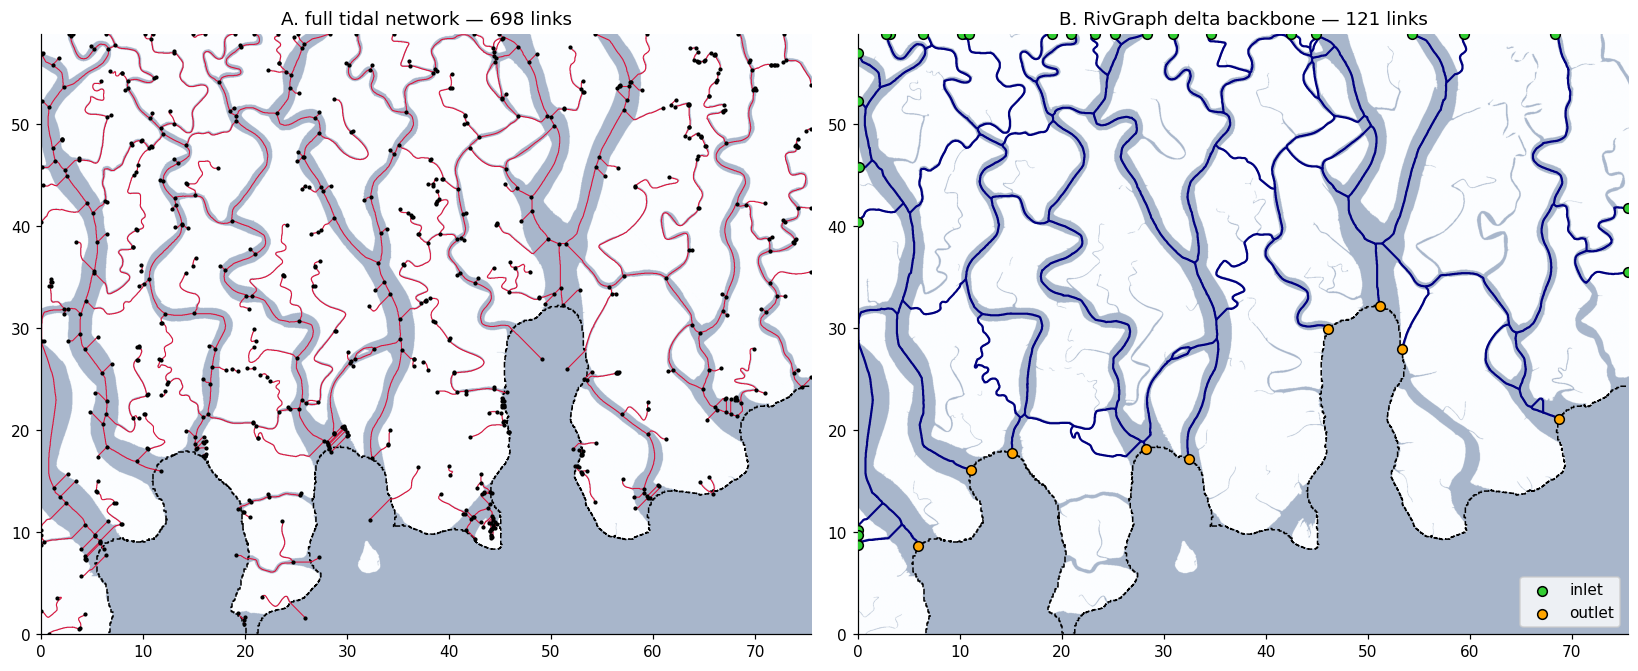

In [8]:
def draw(G, ax, color, lw=0.8, node_color=None, s=4):
    pos = nx.get_node_attributes(G, 'pos')
    for *_, d in G.edges(data=True):
        rr, cc = np.unravel_index(d['idx'], rn.imshape)
        ax.plot((cc + 0.5) * px_x / 1e3, EXT_KM[3] - (rr + 0.5) * px_y / 1e3, color=color, lw=lw)
    if node_color is not None:
        xy = np.array([pos[n] for n in G.nodes])
        ax.scatter((xy[:, 0] - west) / 1e3, (xy[:, 1] - south) / 1e3, s=s, c=node_color, zorder=3)

fig, axs = plt.subplots(1, 2, figsize=(15, 6))
for ax in axs:
    ax.imshow(water, cmap='Blues', alpha=0.35, extent=EXT_KM)
    gpd.GeoSeries([shore]).translate(-west, -south).scale(1e-3, 1e-3, origin=(0, 0)).plot(ax=ax, color='k', lw=1, ls='--')
    ax.set_xlim(EXT_KM[:2]); ax.set_ylim(EXT_KM[2:])
draw(GA, axs[0], 'crimson', 0.7, 'k', 3)
axs[0].set_title(f'A. full tidal network — {GA.number_of_edges()} links')
draw(GB, axs[1], 'navy', 1.4)
pos = nx.get_node_attributes(GB, 'pos')
for key, col, lab in [('inlets', 'limegreen', 'inlet'), ('outlets', 'orange', 'outlet')]:
    xy = np.array([pos[n] for n in rn.nodes[key] if n in pos])
    axs[1].scatter((xy[:, 0] - west) / 1e3, (xy[:, 1] - south) / 1e3, s=40, c=col, ec='k', zorder=4, label=lab)
axs[1].legend(loc='lower right'); axs[1].set_title(f'B. RivGraph delta backbone — {GB.number_of_edges()} links')
plt.tight_layout(); plt.savefig(f'{OUT}/graphs_A_B.png', dpi=130); plt.show()

## 5. Network parameters

### 5a. Whole-graph parameters (A and B)

| Parameter | Formula | Meaning for a delta |
|---|---|---|
| loops (cyclomatic number) | E − V + C | independent loops — **0 for a tree**, the brief's "how far from a tree" |
| meshedness α | (E − V + C) / (2V − 5) | loops ÷ max possible in a planar graph (0 = tree, 1 = fully meshed) |
| β index | E / V | links per node |
| dead-end fraction | share of nodes with degree 1 | tidal creeks that end blindly in the forest |
| median link width | RivGraph `wid_adj`, metres | the mean is dominated by a few multi-km estuary reaches |
| channel length / drainage density | Σ link length, ÷ delta-plain area | how dissected the islands are |
| mean / max degree centrality | deg / (V − 1) | ⚠ in a planar river graph degrees are almost only 1, 3, 4, so this mostly tracks 1/V |
| mean & max betweenness (length-weighted) | share of shortest paths through a node | how much the network depends on a few trunk junctions |
| global efficiency | mean of 1 / shortest-path-hops | how easily any point reaches any other |
| algebraic connectivity λ₂ | 2nd-smallest Laplacian eigenvalue | how hard it is to cut the network in two (robustness) |
| Kirchhoff index | V · trace(L⁺) | total resistance distance: lower = more parallel paths |
| diameter | longest shortest path (hops) | |

In [9]:
def graph_metrics(G, area_km2):
    V, E, C = G.number_of_nodes(), G.number_of_edges(), nx.number_connected_components(G)
    deg = np.array([d for _, d in G.degree()])
    S = nx.Graph()                                      # simple graph for path-based measures (parallel edges -> shortest)
    for u, v, d in G.subgraph(max(nx.connected_components(G), key=len)).edges(data=True):
        if u == v: continue
        if not S.has_edge(u, v) or d['length'] < S[u][v]['length']:
            S.add_edge(u, v, length=d['length'])
    bc = nx.betweenness_centrality(S, weight='length')
    lam = np.linalg.eigvalsh(nx.laplacian_matrix(S, weight=None).toarray().astype(float))
    lengths = [d['length'] for *_, d in G.edges(data=True)]
    widths = [d['width'] for *_, d in G.edges(data=True)]
    return {
        'nodes V': V, 'links E': E, 'components C': C, 'largest component share of nodes': S.number_of_nodes() / V,
        'loops (E-V+C)': E - V + C,
        'meshedness α': (E - V + C) / (2 * V - 5),
        'beta E/V': E / V,
        'dead-end fraction (deg 1)': np.mean(deg == 1),
        'junctions deg 3 frac': np.mean(deg == 3), 'deg >=4 frac': np.mean(deg >= 4),
        'mean degree': deg.mean(),
        'mean degree centrality': deg.mean() / (V - 1),
        'total channel length km': sum(lengths) / 1e3,
        'drainage density km/km2': sum(lengths) / 1e3 / area_km2,
        'mean link length km': np.mean(lengths) / 1e3,
        'median link width m': np.median(widths),
        'mean betweenness': np.mean(list(bc.values())), 'max betweenness': max(bc.values()),
        'global efficiency': nx.global_efficiency(S),
        'algebraic connectivity λ2': lam[1],
        'Kirchhoff index': S.number_of_nodes() * np.sum(1 / lam[1:]),
        'diameter (hops)': nx.diameter(S),
    }, bc

area = landpoly.area / 1e6
mA, bcA = graph_metrics(GA, area)
mB, bcB = graph_metrics(GB, area)
summary = pd.DataFrame({'A. full tidal network': mA, 'B. delta backbone': mB})
summary.style.format('{:.3g}')

,A. full tidal network,B. delta backbone
nodes V,742,104
links E,698,121
components C,63,1
largest component share of nodes,0.685,1
loops (E-V+C),19,18
meshedness α,0.0128,0.0887
beta E/V,0.941,1.16
dead-end fraction (deg 1),0.546,0.337
junctions deg 3 frac,0.425,0.663
deg >=4 frac,0.00135,0


### 5b. Directed backbone: recombination factor (Smart & Moruzzi 1971, Tejedor Table 2)

**Forks** = nodes with ≥ 2 outgoing links; **junctions** = nodes with ≥ 2 incoming links.
The ratio is 0 for a pure bifurcating tree (Wax Lake 0.19) and approaches 1 for loopy deltas (Irrawaddy 0.86, Niger 0.77).
Tejedor's deltas have **one apex**. Here the crop gives many inlets, and inlet channels merging on the way down also count as junctions, so values above 1 are expected.
Compare this number between our own dates, not with Table 2.

In [10]:
forks = sum(1 for n in DB if DB.out_degree(n) >= 2)
juncs = sum(1 for n in DB if DB.in_degree(n) >= 2)
print(f'forks {forks}, junctions {juncs}, recombination factor = {juncs / forks:.3f}')
print('flow directions assigned without cycles:', nx.is_directed_acyclic_graph(DB))

forks 26, junctions 43, recombination factor = 1.654
flow directions assigned without cycles: True


### 5c. Tejedor et al. (2015) metrics — `rn.compute_topologic_metrics()`

Computed per **outlet subnetwork** (everything that drains to one sea outlet). With several inlets RivGraph adds a virtual super-apex;
`inlet='width'` splits the incoming flux between inlets in proportion to channel width. Dynamic metrics use width as the flux surrogate (as in the paper).

| Metric | Low value | High value |
|---|---|---|
| n_alt_paths | single path (tree) | many routes apex → outlet |
| resistance_distance | many parallel paths | 1 = single path |
| top_link_sharing_idx | subnetwork's links are its own | links shared with many outlets |
| leakage_idx | subnetwork keeps its flux | leaks flux to neighbours |
| flux_sharing_idx | flux reaches this outlet | flux shared with other outlets |
| top/dyn mutual information | — | rigid, constrained routing |
| top/dyn conditional entropy | — | flexible routing, many choices |

In [11]:
tm = rn.compute_topologic_metrics(inlet='width')
per_outlet = {}
for k, v in tm.items():
    a = np.asarray(v, dtype=float) if not isinstance(v, (float, int)) else None
    if a is not None and a.ndim == 2 and a.shape[1] == 2:
        per_outlet[k] = pd.Series(a[:, 1], index=a[:, 0].astype(int))
tejedor = pd.DataFrame(per_outlet); tejedor.index.name = 'outlet node'
print('nonlocal entropy rate:', round(tm['nonlin_entropy_rate'], 3),
      '| P(random partition exceeds it):', round(tm['nER_prob_exceedence'], 2))
tejedor.round(3)

nonlocal entropy rate: 0.537 | P(random partition exceeds it): 0.82


,top_mutual_info,top_conditional_entropy,top_link_sharing_idx,n_alt_paths,resistance_distance,flux_sharing_idx,leakage_idx,dyn_mutual_info,dyn_conditional_entropy
outlet node,,,,,,,,,
95,4.075,0.831,0.838,35.0,0.486,0.722,0.127,4.179,0.512
96,4.193,0.826,0.834,70.0,0.572,0.936,0.138,4.180,0.519
97,3.905,0.842,0.799,24.0,0.554,0.452,0.110,4.096,0.468
98,4.602,0.927,0.810,97.0,0.609,0.798,0.106,4.589,0.635
99,5.289,0.951,0.747,471.0,0.672,0.882,0.086,5.203,0.693
100,5.204,0.940,0.762,469.0,0.529,0.945,0.094,5.100,0.684
101,1.823,-0.000,0.663,1.0,1.000,0.571,0.552,1.657,-0.000
102,5.484,0.979,0.658,1890.0,0.633,0.518,0.061,5.420,0.710
103,2.244,0.778,0.198,3.0,0.550,0.067,0.403,2.043,0.138


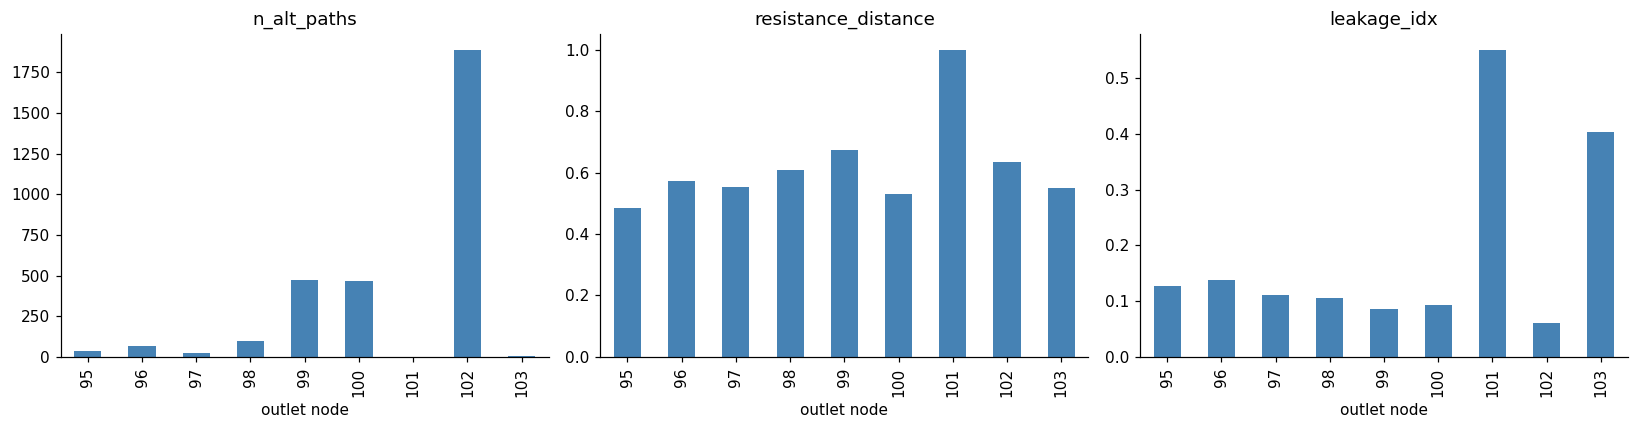

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, k in zip(axs, ['n_alt_paths', 'resistance_distance', 'leakage_idx']):
    tejedor[k].plot.bar(ax=ax, color='steelblue'); ax.set_title(k); ax.set_xlabel('outlet node')
plt.tight_layout(); plt.show()

### 5d. Where are the important nodes? (betweenness centrality on Graph A)

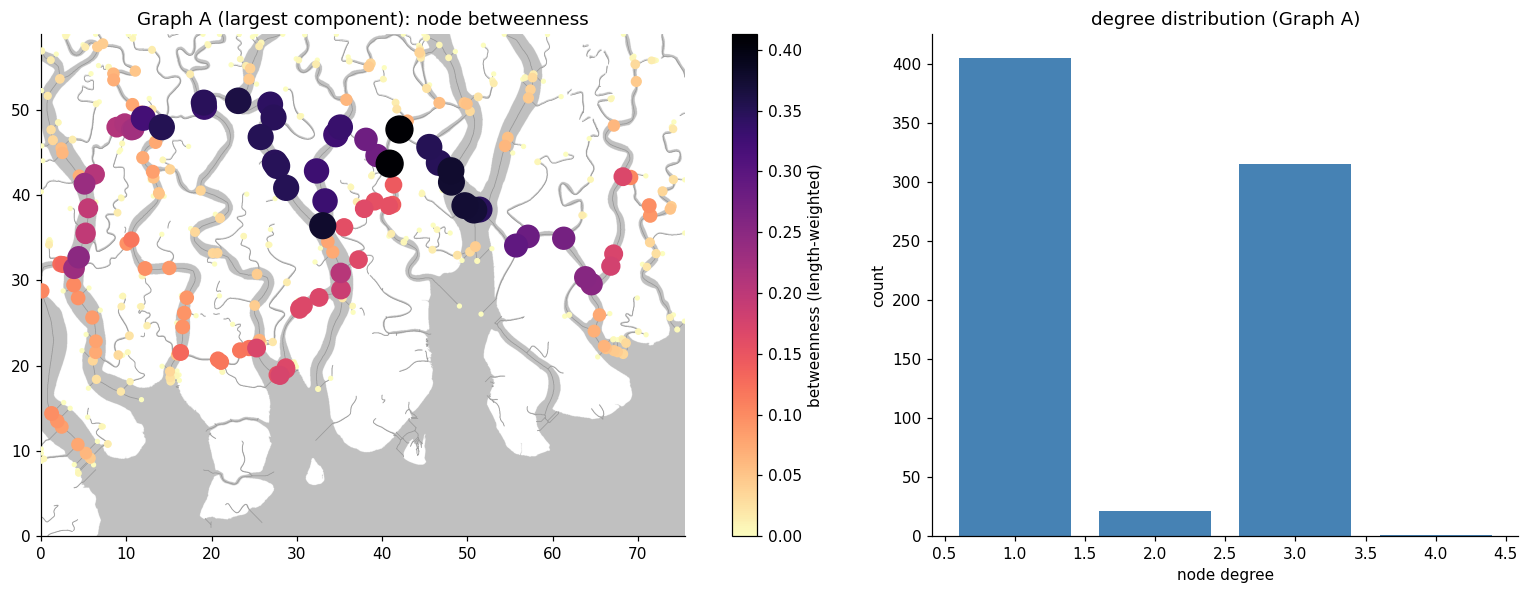

In [13]:
fig, axs = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axs[0]
ax.imshow(water, cmap='Greys', alpha=0.25, extent=EXT_KM)
draw(GA, ax, '0.6', 0.5)
pos = nx.get_node_attributes(GA, 'pos'); ns = [n for n in GA.nodes if n in bcA]
xy = np.array([pos[n] for n in ns]); val = np.array([bcA[n] for n in ns])
o = np.argsort(val)
sc = ax.scatter((xy[o, 0] - west) / 1e3, (xy[o, 1] - south) / 1e3, c=val[o], s=6 + 300 * val[o] / val.max(), cmap='magma_r', zorder=3)
plt.colorbar(sc, ax=ax, label='betweenness (length-weighted)'); ax.set_title('Graph A (largest component): node betweenness')
deg = np.array([d for _, d in GA.degree()])
axs[1].bar(*np.unique(deg, return_counts=True), color='steelblue'); axs[1].set_xlabel('node degree'); axs[1].set_ylabel('count')
axs[1].set_title('degree distribution (Graph A)')
plt.tight_layout(); plt.savefig(f'{OUT}/betweenness_A.png', dpi=130); plt.show()

## 6. One row per image — the record we will build for every date

In [14]:
row = {'date': '2016-01-18', 'season': 'winter (post-monsoon)', 'water_fraction': water.mean(), 'delta_plain_km2': area}
row |= {f'A_{k}': v for k, v in mA.items()}
row |= {f'B_{k}': v for k, v in mB.items()}
row |= {'B_recombination_factor': juncs / forks, 'B_n_inlets': len(rn.nodes['inlets']), 'B_n_outlets': len(rn.nodes['outlets']),
        'B_nonlocal_entropy_rate': tm['nonlin_entropy_rate']}
row |= {f'B_mean_{k}': tejedor[k].mean() for k in tejedor.columns}
record = pd.DataFrame([row])
record.to_csv(f'{OUT}/metrics_2016-01-18.csv', index=False)
record.T.rename(columns={0: 'value'})

,value
date,2016-01-18
season,winter (post-monsoon)
water_fraction,0.409801
delta_plain_km2,3422.981192
A_nodes V,742
...,...
B_mean_resistance_distance,0.622623
B_mean_flux_sharing_idx,0.654574
B_mean_leakage_idx,0.186342
B_mean_dyn_mutual_info,4.051953


## 7. What this example shows and what to watch for

Numbers below are from this run (18 Jan 2016, ~30 m).

* **Mostly dead ends.** 55% of Graph A's nodes are dead ends (degree 1). RivGraph's delta pruning keeps 121 of the 698 land-side links (17%), about half the channel length.
  For the Sundarbans, Graph A is the better description. Graph B is what Tejedor's apex→sea framework can handle.
* **How far from a tree?** Graph A has only 19 independent loops (meshedness 0.013). 18 of them are in the backbone, so at this resolution the loops are carried by the big channels and the small creeks hang off them as dead ends.
  Within the backbone the loops multiply: the number of alternative inlet→outlet paths per outlet ranges from 1 to 1,890.
  At 10 m many creeks that break apart here would reconnect, so expect more loops. That is the resolution question in the brief.
* **A few junctions carry the network.** Betweenness peaks at a chain of junctions in the north-centre (max 0.41): a large share of all shortest paths pass through them. These are the nodes whose change over time is worth watching.
* **Outlets differ a lot.** Leakage index ranges from 0.06 (outlet 102, which keeps nearly all its flux) to 0.55 (outlet 101, a single-path outlet that leaks most of its flux to neighbours).
* **Cropping matters.** The image cuts channels at its edges, and the shoreline splits the scene into separate estuary systems, so Graph B covers only the largest one.
  Use exactly the same footprint for every date, or the counts aren't comparable.
* **Resolution.** At ~30 m, creeks narrower than ~1–2 pixels break apart and drop out of Graph A. Use the same resolution every time. Repeating at 10/30/90 m is the scale question in the brief.
* **Tide and season.** Water extent depends on the tide stage when the image was taken. Record the tide for every scene before reading trends.
* **Directionality.** The flow directions come from RivGraph's river-delta heuristics. Tidal channels flow both ways, so read the dynamic (flux) metrics as an "inlet → sea" model.